# Assignment 1: the Izhikevich neuron model

The goal is to integrate the Izhikevich model with RK4 and reproduce the firing patterns of Figure 2 of the original paper (Part 1 of the assignment). Part 2 (optional) simulates the network of 1000 neurons from the same paper.

*Neural Networks 2026 — FaMAF, Universidad Nacional de Córdoba. English version of the group notebook (Mariel Anachuri, Camila Giolitto, Martín Robins).*

## The Izhikevich model

The Izhikevich model (ref. 1) is a simplification of the well-known model that Hodgkin and Huxley introduced in 1952 (ref. 2, Nobel Prize in Physiology or Medicine 1963) to describe the behaviour of the action potential of a neuron.

The model is described by the following two-dimensional, first-order ODE

$$
\begin{array}{rcl}
v'(t) &=& 0.04\,v^2(t) + 5\,v(t) + 140 - u(t) + I(t) \\
u'(t) &=& a\,\big(b\,v(t) - u(t)\big)
\end{array}
$$

together with the potential *reset* mechanism

$$
\begin{array}{rcl}
v(t) &\leftarrow& c \\
u(t) &\leftarrow& u(t) + d
\end{array}
$$

which emulates the firing of the neuron and is applied when the condition $v(t) \geq 30$ mV is met.

The variable $v$ represents the membrane potential (in mV) and $u$ is a recovery variable, which summarises slow ionic processes and provides negative feedback on $v$. The model parameters are:

- $a$: time scale of the recovery of $u$.
- $b$: how strongly $u$ responds to subthreshold variations of $v$.
- $c$: value to which $v$ is reset after a spike.
- $d$: increment of $u$ after a spike.

In addition, we consider the time-dependent function $I:\mathbb{R}\ni t\to I(t)\in \mathbb{R}$, which represents an input current that excites the neuron. Time is measured in ms.

The value $v = 30$ mV is the one the algorithm uses to record the spike peak and apply the reset; it is not a fixed physiological threshold. Spike initiation depends on the previous state of $v$ and $u$.

Guide 6 of the course writes the same model with other names: $g_2 = 0.04$, $g_1 = 5$, $g_0 = 140$, $v_+ = 30$; the guide's $b$ is $a$ here, its $c$ is $b$ here, $v_-$ is $c$ and $\Delta u$ is $d$.

References:

1. [Eugene M. Izhikevich, Simple Model of Spiking Neurons, IEEE Transactions on Neural Networks, vol. 14, no. 6, p. 1569, November 2003](https://ieeexplore.ieee.org/document/1257420) ([open-access PDF](https://www.izhikevich.org/publications/spikes.pdf))
2. https://en.wikipedia.org/wiki/Hodgkin%E2%80%93Huxley_model

## Environment setup

Libraries used in the notebook. The plot style below uses the Montserrat font if the file `Montserrat-Regular.ttf` is next to the notebook; otherwise matplotlib's default font is used.

In [1]:
import numpy                   as np
import matplotlib.pyplot       as plt
import matplotlib.font_manager as fm

Plot style

In [2]:
import os

FONT = 'Montserrat-Regular.ttf'

COLOR      = '#2a78d6'
ORANGE     = '#eb6834'
BACKGROUND = '#fcfcfb'
GRID       = '#e4e3df'
TEXT       = '#52514e'
TITLE      = '#0b0b0b'

plt.rcParams.update(
                    {
                     'figure.facecolor'   : '#ffffff',
                     'axes.facecolor'     : BACKGROUND,
                     'axes.edgecolor'     : GRID,
                     'axes.grid'          : True,
                     'axes.axisbelow'     : True,
                     'axes.labelcolor'    : TEXT,
                     'axes.titlecolor'    : TITLE,
                     'axes.titlelocation' : 'left',
                     'grid.color'         : GRID,
                     'grid.linewidth'     : 0.8,
                     'xtick.color'        : TEXT,
                     'ytick.color'        : TEXT,
                    }
                   )

# The Montserrat font is optional: if the file is not next to the notebook,
# matplotlib's default font is used
if os.path.exists(FONT):
    fm.fontManager.addfont(FONT)
    plt.rcParams['font.family'] = fm.FontProperties(fname = FONT).get_name()

## 1. Input current

Item 1: $I_0(t) = 0$ if $t < 10$ ms and $I_0(t) = 10$ if $t \geq 10$ ms.

In [3]:
def I0(t):
    if t < 10:
        return 0.0
    else:
        return 10.0

## 2. Parameters, initial condition and time grid

Values from item 1. The initial condition $u(0) = b\,v(0)$ corresponds to the resting state of the neuron. The list `spikes` stores the spike times. The integration covers $t \in [0, 100]$ ms with step $h = 0.1$ ms, that is, $k = 1000$ steps.

In [4]:
v_peak = 30.0

p = {
     'a'      : 0.02,
     'b'      : 0.2,
     'c'      : -65.0,
     'd'      : 2.0,
     'I'      : I0,
     'spikes' : [],
    }

v0 = -70.0
u0 = p['b'] * v0
x0 = np.array([v0, u0])

t0 = 0.0
tf = 100.0
h  = 0.1
k  = round((tf - t0) / h)

print('Initial condition (v, u):', x0)
print('Integration steps       :', k)

Initial condition (v, u): [-70. -14.]
Integration steps       : 1000


## 3. Model equations

`f_izh` returns $(v', u')$ with the signature `f(x, t, p)` that the integrator expects. At rest, before the stimulus, both derivatives must be zero.

In [5]:
def f_izh(x, t, p):
    v = x[0]
    u = x[1]

    dv = 0.04 * v**2 + 5 * v + 140 - u + p['I'](t)
    du = p['a'] * (p['b'] * v - u)

    return np.array([dv, du])


print('Derivatives at t = 0 :', f_izh(x0, 0, p))

Derivatives at t = 0 : [0. 0.]


## 4. Reset

It is used as the conditioning function of the integrator: after each step, if $v \geq 30$ mV, it records the spike and applies $v \leftarrow c$, $u \leftarrow u + d$.

In [6]:
def reset(x, t, p):
    if x[0] >= v_peak:
        p['spikes'].append(t)

        x[0] = p['c']
        x[1] = x[1] + p['d']

    return x

## 5. Integrator

`rk4` computes one step of the fourth-order Runge-Kutta method: given $x(t)$, it returns $x(t+h)$. `ode_integrator` (from Guide 4) repeats that step `k` times and, after each one, applies the conditioning function `c`, which here will be `reset`. It returns the times `t` and the matrix `w`, whose row 0 is $v$ and row 1 is $u$.

In [7]:
def rk4(f, x, t, h, p):
    k1 = f(x, t, p)
    k2 = f(x + 0.5 * h * k1, t + 0.5 * h, p)
    k3 = f(x + 0.5 * h * k2, t + 0.5 * h, p)
    k4 = f(x + h * k3, t + h, p)

    return x + h * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0


def ode_integrator(m, f, xa, t_ini, t_fin, k, p, c = lambda x, t, p: x):
    n = len(xa)
    h = (t_fin - t_ini) / k

    t = np.zeros(k + 1)
    w = np.zeros((n, k + 1))

    t[0]    = t_ini
    w[:, 0] = xa

    for j in range(k):
        t[j + 1]    = t[j] + h                         # advance the time
        w[:, j + 1] = m(f, w[:, j], t[j], h, p)        # one step of the method (rk4)
        w[:, j + 1] = c(w[:, j + 1], t[j + 1], p)      # conditioning function (reset)

    return t, w

## 6. Integration (item 1)

The list of spikes is emptied and the model is integrated with RK4 over $t \in [0, 100]$ ms. Row 0 of `w` is $v(t)$ and row 1 is $u(t)$.

In [8]:
p['spikes'] = []

t, w = ode_integrator(rk4, f_izh, x0, t0, tf, k, p, reset)

v      = w[0, :]
u      = w[1, :]
spikes = np.array(p['spikes'])

print('Spikes           :', len(spikes))
print('Spike times (ms) :', spikes.round(1))

Spikes           : 7
Spike times (ms) : [13.5 17.1 21.9 29.5 44.7 63.7 82.6]


## 7. Plot of $v$, $u$ and $I$ (item 2)

One panel per quantity, with a shared time axis. The dashed line marks the onset of the stimulus.

The reset is applied in the same step in which $v$ exceeds 30 mV, so the value stored at that instant is already $c$ and the peak is not kept in `v`. For plotting, at each spike the point $(t_{\text{spike}}, 30)$ is inserted just before the reset value: the curve rises to 30 mV and from there drops to $c$.

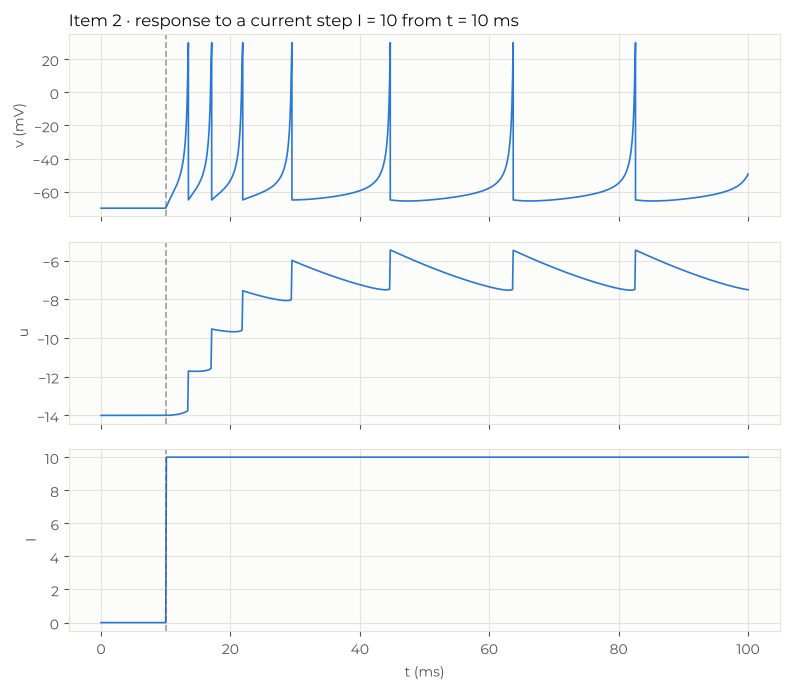

In [9]:
t_stimulus = 10.0

I = np.zeros(len(t))

for j in range(len(t)):
    I[j] = p['I'](t[j])

spike_indices = np.searchsorted(t, spikes)

t_plot = np.insert(t, spike_indices, spikes)
v_plot = np.insert(v, spike_indices, v_peak)

fig, ax = plt.subplots(3, 1, sharex = True, figsize = (8, 7))

ax[0].plot(t_plot, v_plot, lw = 1.2, color = COLOR)
ax[0].set_title('Item 2 · response to a current step I = 10 from t = 10 ms')
ax[0].set_ylabel('v (mV)')

ax[1].plot(t, u, lw = 1.2, color = COLOR)
ax[1].set_ylabel('u')

ax[2].plot(t, I, lw = 1.2, color = COLOR)
ax[2].set_ylabel('I')
ax[2].set_xlabel('t (ms)')

for axis in ax:
    axis.axvline(t_stimulus, ls = '--', lw = 1.2, color = TEXT, alpha = 0.55)

plt.tight_layout()
plt.show()

## 8. Currents for item 3

Each case of Figure 2 is stimulated with one of four current protocols:

| Current | Cases | What it is |
|---|---|---|
| $I_1$ | RS, IB, CH, FS, LTS | Strong step from 20 ms |
| $I_2$ | TC1 | Weak step from 20 ms |
| $I_3$ | TC2 | Negative (hyperpolarising) pulse between 20 and 80 ms |
| $I_4$ | RZ | Small constant current from 40 ms, plus a 1 ms pulse at 180 ms |

The intervals are evaluated in order: `elif` is only reached if the previous conditions failed, so it is enough to write the upper end of each interval.

In [10]:
def I1(t):
    if t < 20:
        return 0.0
    else:
        return 10.0


def I2(t):
    if t < 20:
        return 0.0
    else:
        return 1.0


def I3(t):
    if t < 20:
        return 0.0
    elif t < 80:
        return -25.0
    else:
        return 0.0


def I4(t):
    if t < 40:
        return 0.0
    elif t < 180:
        return 0.2
    elif t < 181:
        return 2.2
    else:
        return 0.2

## 9. Parameters of the eight cases

Each case is defined by its parameters $a, b, c, d$, the current that stimulates it, the initial potential $v(0)$ (with $u(0) = b\,v(0)$) and the simulation length `tf`. The length is our choice for this assignment; 200 ms are enough to see each pattern, except RZ, whose pulse arrives at 180 ms.

In [11]:
cases = {
         'RS'  : {'a': 0.02, 'b': 0.20, 'c': -65.0, 'd': 8.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
         'IB'  : {'a': 0.02, 'b': 0.20, 'c': -55.0, 'd': 4.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
         'CH'  : {'a': 0.02, 'b': 0.20, 'c': -50.0, 'd': 2.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
         'FS'  : {'a': 0.10, 'b': 0.20, 'c': -65.0, 'd': 2.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
         'TC1' : {'a': 0.02, 'b': 0.25, 'c': -65.0, 'd': 0.05, 'I': I2, 'v0': -63.0, 'tf': 200.0},
         'TC2' : {'a': 0.02, 'b': 0.25, 'c': -65.0, 'd': 0.05, 'I': I3, 'v0': -65.0, 'tf': 200.0},
         'RZ'  : {'a': 0.10, 'b': 0.26, 'c': -65.0, 'd': 2.00, 'I': I4, 'v0': -62.5, 'tf': 300.0},
         'LTS' : {'a': 0.02, 'b': 0.25, 'c': -65.0, 'd': 2.00, 'I': I1, 'v0': -65.0, 'tf': 200.0},
        }

print('Cases:', list(cases.keys()))

Cases: ['RS', 'IB', 'CH', 'FS', 'TC1', 'TC2', 'RZ', 'LTS']


## 10. The cases in parameter space

As in Figure 2 of the paper, each case is placed on two planes: $(a, b)$, which governs the dynamics of $u$, and $(c, d)$, which governs the reset. Several cases share the same point on one plane and differ on the other, so the names are grouped by coordinate.

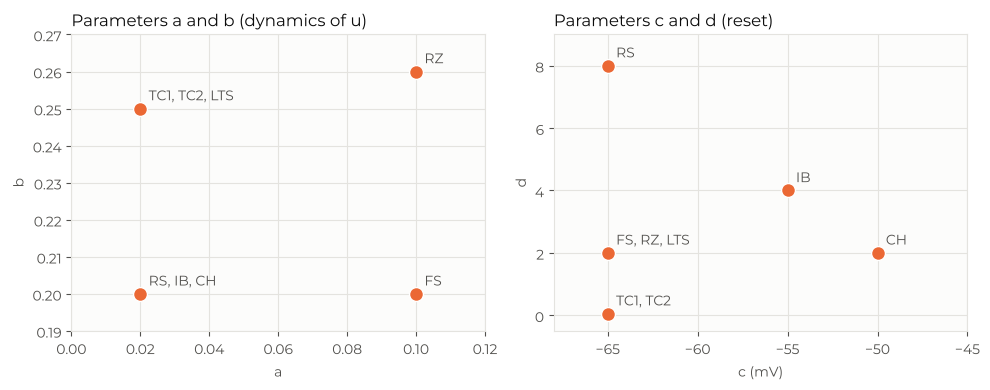

In [12]:
groups_ab = {}
groups_cd = {}

for name in cases:
    params = cases[name]

    point_ab = (params['a'], params['b'])
    point_cd = (params['c'], params['d'])

    if point_ab not in groups_ab:
        groups_ab[point_ab] = []
    if point_cd not in groups_cd:
        groups_cd[point_cd] = []

    groups_ab[point_ab].append(name)
    groups_cd[point_cd].append(name)

fig, ax = plt.subplots(1, 2, figsize = (10, 4))

for axis, groups in [(ax[0], groups_ab), (ax[1], groups_cd)]:
    for point in groups:
        axis.scatter(point[0], point[1], s = 100, color = ORANGE, edgecolors = '#ffffff', zorder = 3)
        axis.annotate(
                      ', '.join(groups[point]),
                      point,
                      xytext     = (6, 6),
                      textcoords = 'offset points',
                      color      = TEXT,
                     )

ax[0].set_title('Parameters a and b (dynamics of u)')
ax[0].set_xlabel('a')
ax[0].set_ylabel('b')
ax[0].set_xlim(0, 0.12)
ax[0].set_ylim(0.19, 0.27)

ax[1].set_title('Parameters c and d (reset)')
ax[1].set_xlabel('c (mV)')
ax[1].set_ylabel('d')
ax[1].set_xlim(-68, -45)
ax[1].set_ylim(-0.5, 9)

plt.tight_layout()
plt.show()

## 11. Integration of the eight cases

For each case, the dictionary `p` is built with its parameters and its current, the list of spikes is emptied and the model is integrated with RK4 from $v(0)$, $u(0) = b\,v(0)$ up to `tf`, with the same step $h = 0.1$ ms. The results are stored in `results`, with the same dictionary-of-dictionaries structure as `cases`. Together with $v$, the curve for plotting is stored, with the 30 mV peak inserted at each spike (section 7).

In [13]:
results = {}

for name in cases:
    params = cases[name]

    p_case = {
              'a'      : params['a'],
              'b'      : params['b'],
              'c'      : params['c'],
              'd'      : params['d'],
              'I'      : params['I'],
              'spikes' : [],
             }

    x0_case = np.array([params['v0'], params['b'] * params['v0']])
    k_case  = round((params['tf'] - t0) / h)

    t_case, w_case = ode_integrator(rk4, f_izh, x0_case, t0, params['tf'], k_case, p_case, reset)

    spikes_case   = np.array(p_case['spikes'])
    spike_indices = np.searchsorted(t_case, spikes_case)

    results[name] = {
                     't'      : t_case,
                     'v'      : w_case[0, :],
                     'u'      : w_case[1, :],
                     'spikes' : spikes_case,
                     't_plot' : np.insert(t_case, spike_indices, spikes_case),
                     'v_plot' : np.insert(w_case[0, :], spike_indices, v_peak),
                    }

    print(f'{name:4s}: {len(spikes_case):3d} spikes')

RS  :   5 spikes


IB  :   8 spikes
CH  :  17 spikes
FS  :  25 spikes
TC1 :   4 spikes
TC2 :   5 spikes
RZ  :   3 spikes
LTS :  17 spikes


## 12. Cases stimulated with $I_1$: RS, IB, CH, FS and LTS

All five receive the same step $I_1$ from 20 ms, so the differences between panels are due only to the parameters. The panels share their axes so that they can be compared; the dashed line marks the onset of the stimulus.

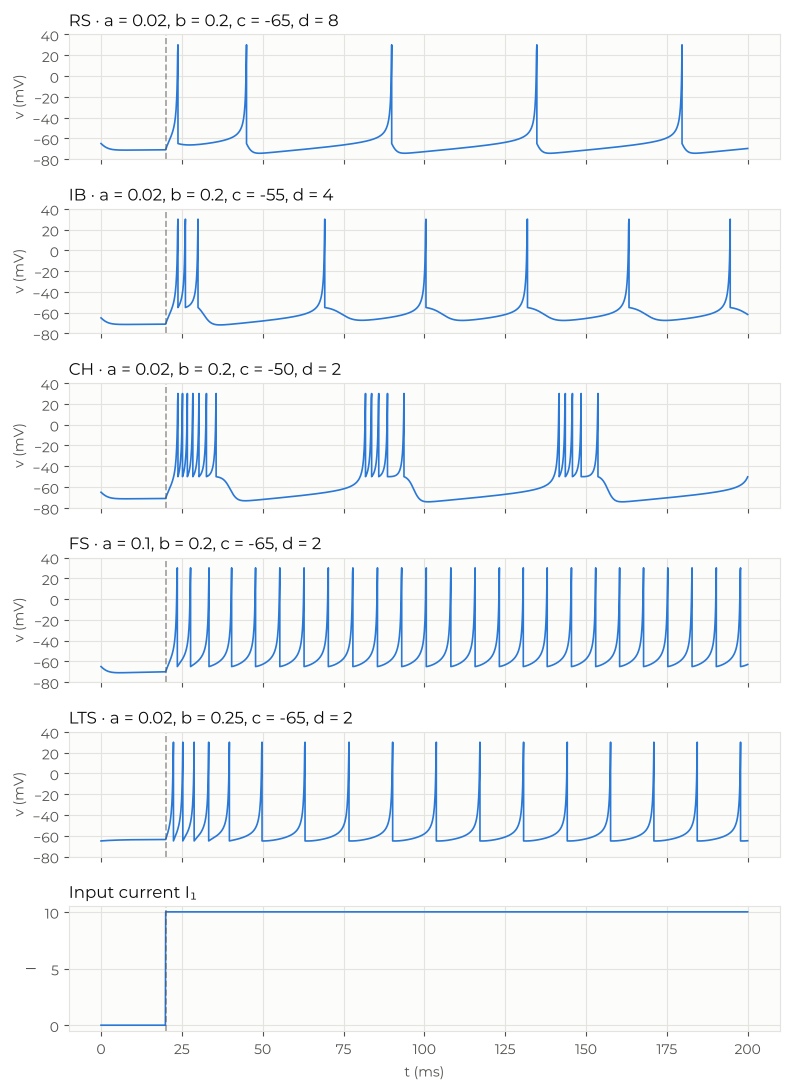

In [14]:
cases_I1 = ['RS', 'IB', 'CH', 'FS', 'LTS']

fig, ax = plt.subplots(len(cases_I1) + 1, 1, sharex = True, figsize = (8, 11))

for i, name in enumerate(cases_I1):
    params = cases[name]
    result = results[name]

    ax[i].plot(result['t_plot'], result['v_plot'], lw = 1.2, color = COLOR)
    ax[i].set_title(f"{name} · a = {params['a']}, b = {params['b']}, c = {params['c']:.0f}, d = {params['d']:.0f}")
    ax[i].set_ylabel('v (mV)')
    ax[i].set_ylim(-80, 40)
    ax[i].set_yticks(np.arange(-80, 41, 20))

t_I1 = results['RS']['t']
I_1  = np.zeros(len(t_I1))

for j in range(len(t_I1)):
    I_1[j] = I1(t_I1[j])

ax[-1].plot(t_I1, I_1, lw = 1.2, color = COLOR)
ax[-1].set_title('Input current I₁')
ax[-1].set_ylabel('I')
ax[-1].set_xlabel('t (ms)')

for axis in ax:
    axis.axvline(20, ls = '--', lw = 1.2, color = TEXT, alpha = 0.55)

plt.tight_layout()
plt.show()

## 13. Case stimulated with $I_2$: TC1

Thalamo-cortical neuron that starts from $v(0) = -63$ mV and receives a weak step from 20 ms: it responds with tonic firing.

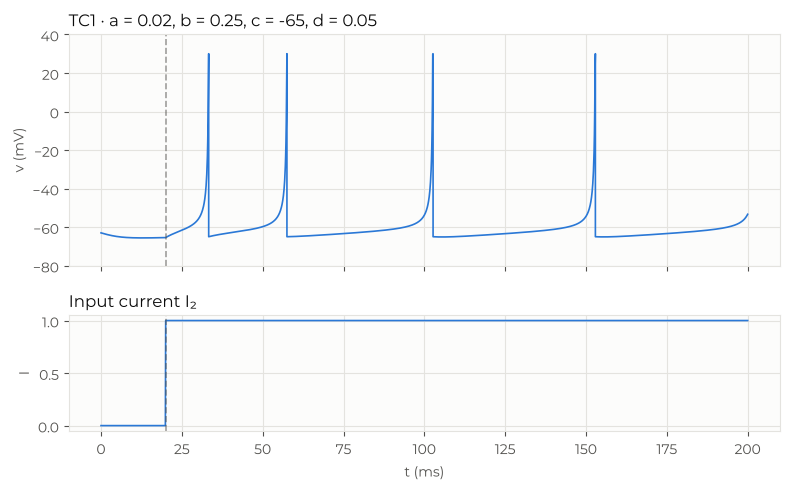

In [15]:
params = cases['TC1']
result = results['TC1']

I_case = np.zeros(len(result['t']))

for j in range(len(result['t'])):
    I_case[j] = I2(result['t'][j])

fig, ax = plt.subplots(
                       2,
                       1,
                       sharex      = True,
                       figsize     = (8, 5),
                       gridspec_kw = {'height_ratios': [2, 1]},
                      )

ax[0].plot(result['t_plot'], result['v_plot'], lw = 1.2, color = COLOR)
ax[0].set_title(f"TC1 · a = {params['a']}, b = {params['b']}, c = {params['c']:.0f}, d = {params['d']}")
ax[0].set_ylabel('v (mV)')
ax[0].set_ylim(-80, 40)
ax[0].set_yticks(np.arange(-80, 41, 20))

ax[1].plot(result['t'], I_case, lw = 1.2, color = COLOR)
ax[1].set_title('Input current I₂')
ax[1].set_ylabel('I')
ax[1].set_xlabel('t (ms)')

for axis in ax:
    for t_change in [20]:
        axis.axvline(t_change, ls = '--', lw = 1.2, color = TEXT, alpha = 0.55)

plt.tight_layout()
plt.show()

## 14. Case stimulated with $I_3$: TC2

The same thalamo-cortical neuron receives a negative pulse between 20 and 80 ms, which hyperpolarises it; when the pulse is removed, it responds with a rebound burst. The $v$ axis goes down to $-100$ mV to show the hyperpolarisation.

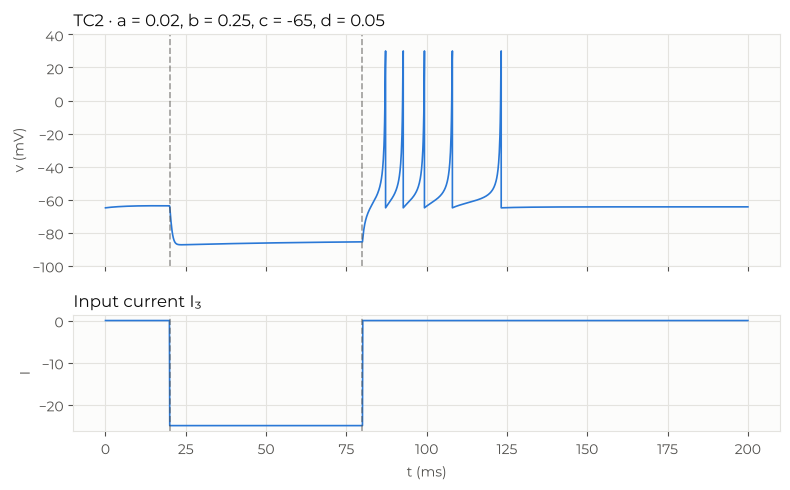

In [16]:
params = cases['TC2']
result = results['TC2']

I_case = np.zeros(len(result['t']))

for j in range(len(result['t'])):
    I_case[j] = I3(result['t'][j])

fig, ax = plt.subplots(
                       2,
                       1,
                       sharex      = True,
                       figsize     = (8, 5),
                       gridspec_kw = {'height_ratios': [2, 1]},
                      )

ax[0].plot(result['t_plot'], result['v_plot'], lw = 1.2, color = COLOR)
ax[0].set_title(f"TC2 · a = {params['a']}, b = {params['b']}, c = {params['c']:.0f}, d = {params['d']}")
ax[0].set_ylabel('v (mV)')
ax[0].set_ylim(-100, 40)
ax[0].set_yticks(np.arange(-100, 41, 20))

ax[1].plot(result['t'], I_case, lw = 1.2, color = COLOR)
ax[1].set_title('Input current I₃')
ax[1].set_ylabel('I')
ax[1].set_xlabel('t (ms)')

for axis in ax:
    for t_change in [20, 80]:
        axis.axvline(t_change, ls = '--', lw = 1.2, color = TEXT, alpha = 0.55)

plt.tight_layout()
plt.show()

## 15. Case stimulated with $I_4$: RZ

The resonator receives a small constant current from 40 ms, which produces damped subthreshold oscillations, and a 1 ms pulse at 180 ms that takes it to the repetitive firing regime.

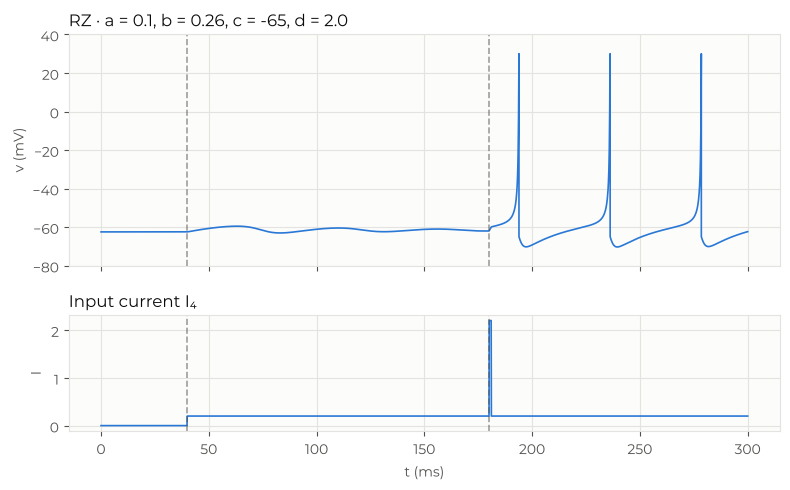

In [17]:
params = cases['RZ']
result = results['RZ']

I_case = np.zeros(len(result['t']))

for j in range(len(result['t'])):
    I_case[j] = I4(result['t'][j])

fig, ax = plt.subplots(
                       2,
                       1,
                       sharex      = True,
                       figsize     = (8, 5),
                       gridspec_kw = {'height_ratios': [2, 1]},
                      )

ax[0].plot(result['t_plot'], result['v_plot'], lw = 1.2, color = COLOR)
ax[0].set_title(f"RZ · a = {params['a']}, b = {params['b']}, c = {params['c']:.0f}, d = {params['d']}")
ax[0].set_ylabel('v (mV)')
ax[0].set_ylim(-80, 40)
ax[0].set_yticks(np.arange(-80, 41, 20))

ax[1].plot(result['t'], I_case, lw = 1.2, color = COLOR)
ax[1].set_title('Input current I₄')
ax[1].set_ylabel('I')
ax[1].set_xlabel('t (ms)')

for axis in ax:
    for t_change in [40, 180]:
        axis.axvline(t_change, ls = '--', lw = 1.2, color = TEXT, alpha = 0.55)

plt.tight_layout()
plt.show()

## 16. The eight cases in a compact figure

Figure for the report, one page wide: a 2 × 4 grid of cases, each with $v(t)$ and, below it, a strip with its input current. The $v$ panels share the vertical axis so that the cases can be compared; each current shows only its extreme values.

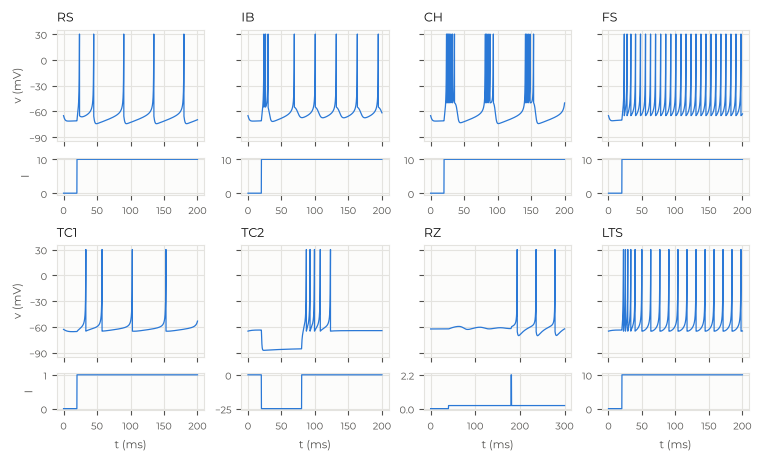

In [18]:
fig = plt.figure(figsize = (7.5, 4.5), layout = 'constrained')
gs  = fig.add_gridspec(4, 4, height_ratios = [3, 1, 3, 1])

for i, name in enumerate(cases):
    row = 2 * (i // 4)
    col = i % 4

    result  = results[name]
    current = cases[name]['I']

    I_case = np.zeros(len(result['t']))

    for j in range(len(result['t'])):
        I_case[j] = current(result['t'][j])

    ax_v = fig.add_subplot(gs[row, col])
    ax_I = fig.add_subplot(gs[row + 1, col], sharex = ax_v)

    ax_v.plot(result['t_plot'], result['v_plot'], lw = 0.9, color = COLOR)
    ax_v.set_title(name, fontsize = 9)
    ax_v.set_ylim(-95, 35)
    ax_v.set_yticks(np.arange(-90, 31, 30))
    ax_v.tick_params(labelsize = 7, labelbottom = False)

    ax_I.plot(result['t'], I_case, lw = 0.9, color = COLOR)
    ax_I.set_yticks([I_case.min(), I_case.max()])
    ax_I.tick_params(labelsize = 7)

    if col == 0:
        ax_v.set_ylabel('v (mV)', fontsize = 8)
        ax_I.set_ylabel('I', fontsize = 8)
    else:
        ax_v.tick_params(labelleft = False)

    if row == 2:
        ax_I.set_xlabel('t (ms)', fontsize = 8)

plt.show()

## 17. Effect of the integration step

To evaluate the numerical error (Figure 4 of the report), the base case of sections 2–6 is integrated again with $h = 0.2$, $0.1$, $0.05$ and $0.01$ ms, taking $h = 0.01$ ms as the reference. The parameters, the current $I_0$ and the initial condition are the same; only the step changes.

In [19]:
steps = [0.2, 0.1, 0.05, 0.01]

runs = {}

for h_test in steps:
    k_test = round((tf - t0) / h_test)

    p['spikes'] = []

    t_test, w_test = ode_integrator(rk4, f_izh, x0, t0, tf, k_test, p, reset)

    spikes_test   = np.array(p['spikes'])
    spike_indices = np.searchsorted(t_test, spikes_test)

    runs[h_test] = {
                    't'      : t_test,
                    'spikes' : spikes_test,
                    't_plot' : np.insert(t_test, spike_indices, spikes_test),
                    'v_plot' : np.insert(w_test[0, :], spike_indices, v_peak),
                   }

    print('h =', h_test, 'ms ->', len(spikes_test), 'spikes:', spikes_test.round(2))

h = 0.2 ms -> 7 spikes: [13.6 17.2 22.  29.8 45.8 65.2 84.4]
h = 0.1 ms -> 7 spikes: [13.5 17.1 21.9 29.5 44.7 63.7 82.6]
h = 0.05 ms -> 7 spikes: [13.45 17.   21.75 29.25 44.25 63.25 82.15]
h = 0.01 ms -> 7 spikes: [13.46 17.   21.71 29.15 44.03 63.01 81.86]


All four steps give seven spikes, so the time of the $k$-th spike can be compared directly with the reference. Top panel: $v(t)$ for each step. Bottom panel: shift $\Delta t_k = t_k(h) - t_k(0.01)$ of each spike with respect to the reference.

h = 0.2 ms -> shift of each spike (ms): [0.14 0.2  0.29 0.65 1.77 2.19 2.54]
h = 0.1 ms -> shift of each spike (ms): [0.04 0.1  0.19 0.35 0.67 0.69 0.74]
h = 0.05 ms -> shift of each spike (ms): [-0.01  0.    0.04  0.1   0.22  0.24  0.29]


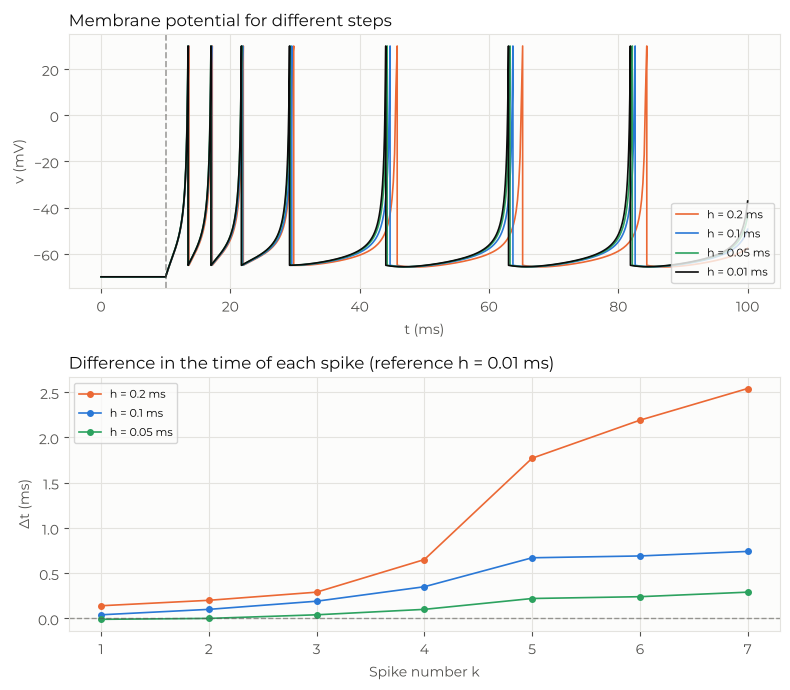

In [20]:
GREEN = '#2ca25f'

colors    = {0.2: ORANGE, 0.1: COLOR, 0.05: GREEN, 0.01: TITLE}
reference = runs[0.01]['spikes']

for h_test in [0.2, 0.1, 0.05]:
    shift = runs[h_test]['spikes'] - reference
    print('h =', h_test, 'ms -> shift of each spike (ms):', shift.round(2))

fig, ax = plt.subplots(2, 1, figsize = (8, 7))

for h_test in steps:
    ax[0].plot(runs[h_test]['t_plot'], runs[h_test]['v_plot'], lw = 1.2, color = colors[h_test], label = f'h = {h_test} ms')

ax[0].axvline(t_stimulus, ls = '--', lw = 1.2, color = TEXT, alpha = 0.55)
ax[0].set_title('Membrane potential for different steps')
ax[0].set_xlabel('t (ms)')
ax[0].set_ylabel('v (mV)')
ax[0].legend(loc = 'lower right', fontsize = 8)

k_spike = np.arange(1, len(reference) + 1)

for h_test in [0.2, 0.1, 0.05]:
    shift = runs[h_test]['spikes'] - reference
    ax[1].plot(k_spike, shift, '-o', ms = 4, lw = 1.2, color = colors[h_test], label = f'h = {h_test} ms')

ax[1].axhline(0, ls = '--', lw = 1.0, color = TEXT, alpha = 0.55)
ax[1].set_title('Difference in the time of each spike (reference h = 0.01 ms)')
ax[1].set_xlabel('Spike number k')
ax[1].set_ylabel('Δt (ms)')
ax[1].legend(loc = 'upper left', fontsize = 8)

plt.tight_layout()
plt.show()

# Part 2 (optional): network of 1000 Izhikevich neurons

Python translation of the MATLAB program in Section IV of the paper. $N_e = 800$ excitatory and $N_i = 200$ inhibitory neurons, with $r_i \sim U(0, 1)$:

* excitatory: $a = 0.02$, $b = 0.2$, $c = -65 + 15 r_i^2$, $d = 8 - 6 r_i^2$ (from RS to CH);
* inhibitory: $a = 0.02 + 0.08 r_i$, $b = 0.25 - 0.05 r_i$, $c = -65$, $d = 2$ (from LTS to FS);
* $S = [\,0.5\,R_E \mid -R_I\,]$, with $s_{ij}$ the weight from the presynaptic neuron $j$ to the postsynaptic neuron $i$.

At each step of 1 ms: thalamic noise $I^{ext}_i = 5\xi_i$ (excitatory) or $2\xi_i$ (inhibitory), **pulse** synaptic input $I^{syn}_i = \sum_{j \in F} s_{ij}$ ($F$ = neurons that fired), two Euler half steps of 0.5 ms for $v$ and one of 1 ms for $u$.

## 18. Network parameters

`network_parameters` draws the random numbers in the same order as the MATLAB code ($r_i$ of the excitatory neurons, $r_i$ of the inhibitory neurons, then $S$). With the same seed, the versions with and without self-connections share $r_i$, $S$ and the noise. `thalamic_noise` draws the external input of each 1 ms step.

In [21]:
from scipy.signal import welch

SEED = 2026          # seed reported in the report


def network_parameters(Ne = 800, Ni = 200, seed = SEED, self_connections = True):
    rng = np.random.default_rng(seed)

    re = rng.random(Ne)
    ri = rng.random(Ni)

    N = Ne + Ni

    a = np.concatenate([0.02 * np.ones(Ne), 0.02 + 0.08 * ri])
    b = np.concatenate([0.2  * np.ones(Ne), 0.25 - 0.05 * ri])
    c = np.concatenate([-65 + 15 * re**2,   -65 * np.ones(Ni)])     # -65 + 15 r^2 (paper)
    d = np.concatenate([8 - 6 * re**2,       2 * np.ones(Ni)])

    # S[i, j]: weight from neuron j (presynaptic) to neuron i (postsynaptic)
    S = np.hstack([0.5 * rng.random((N, Ne)), -rng.random((N, Ni))])

    if not self_connections:
        np.fill_diagonal(S, 0.0)

    return {
            'Ne'  : Ne,
            'Ni'  : Ni,
            'N'   : N,
            'a'   : a,
            'b'   : b,
            'c'   : c,
            'd'   : d,
            'S'   : S,
            'rng' : rng,
           }


def thalamic_noise(p):
    # I_ext: 5 xi for excitatory neurons, 2 xi for inhibitory ones, xi ~ N(0, 1), redrawn every 1 ms
    noise_exc = 5 * p['rng'].standard_normal(p['Ne'])
    noise_inh = 2 * p['rng'].standard_normal(p['Ni'])

    return np.concatenate([noise_exc, noise_inh])

## 19. Literal translation of the paper's MATLAB code

One step = 1 ms. At the beginning of each step, the neurons with $v \geq 30$ are detected and reset; the synaptic input is the sum of the weights of the neurons that fired (pulse coupling), and $v$ is updated with two half steps of Euler ("for numerical stability", as the paper says). The function returns `firings`, a two-column array: spike time (ms) and neuron index.

In [22]:
def network_literal(p, T = 1000):
    v = -65.0 * np.ones(p['N'])
    u = p['b'] * v

    firings = []

    for t in range(T):
        I = thalamic_noise(p)

        fired = np.flatnonzero(v >= 30)                    # indices of the neurons that fired

        for i in fired:
            firings.append([t, i])

        v[fired] = p['c'][fired]                           # reset
        u[fired] = u[fired] + p['d'][fired]

        I = I + p['S'][:, fired].sum(axis = 1)             # coupling by spike events

        v = v + 0.5 * (0.04 * v**2 + 5 * v + 140 - u + I)  # two half steps of 0.5 ms
        v = v + 0.5 * (0.04 * v**2 + 5 * v + 140 - u + I)
        u = u + p['a'] * (p['b'] * v - u)

    return np.array(firings, dtype = float).reshape(-1, 2)

## 20. Measurements: spike count, rates, population activity and spectrum

* `metrics`: total number of spikes and mean rates (Hz per neuron) in $[\text{start}, T)$, for the whole network and for each population.
* `population_activity`: population rate (spikes per neuron in 1 ms bins, in Hz).
* `spectrum`: power spectrum (Welch) of the population rate, discarding the first 100 ms.
* `raster`: raster plot, excitatory neurons in black and inhibitory ones in red.

In [23]:
def metrics(firings, T, N = 1000, Ne = 800, start = 0.0):
    keep     = firings[:, 0] >= start
    t_keep   = firings[keep, 0]
    i_keep   = firings[keep, 1]
    duration = (T - start) * 1e-3                          # in seconds

    return {
            'spikes'      : len(t_keep),
            'rate_Hz'     : len(t_keep) / (N * duration),
            'rate_exc_Hz' : np.sum(i_keep < Ne) / (Ne * duration),
            'rate_inh_Hz' : np.sum(i_keep >= Ne) / ((N - Ne) * duration),
           }


def print_metrics(label, m):
    print(label)
    print('    spikes          :', m['spikes'])
    print('    mean rate (Hz)  :', round(m['rate_Hz'], 3))
    print('    excitatory (Hz) :', round(m['rate_exc_Hz'], 3))
    print('    inhibitory (Hz) :', round(m['rate_inh_Hz'], 3))


def population_activity(firings, T, N = 1000, bin_ms = 1.0):
    bins      = np.arange(0, T + bin_ms, bin_ms)
    counts, _ = np.histogram(firings[:, 0], bins)

    return bins[:-1], counts / (N * bin_ms * 1e-3)         # Hz per neuron


def spectrum(firings, T, N = 1000, discard = 100.0):
    t_bins, rate = population_activity(firings, T, N)
    x = rate[t_bins >= discard]

    freqs, power = welch(x - x.mean(), fs = 1000, nperseg = min(512, len(x)))

    return freqs, power


def raster(axis, firings, Ne = 800, T = 1000, ms = 1.2):
    excitatory = firings[:, 1] < Ne
    inhibitory = firings[:, 1] >= Ne

    axis.plot(firings[excitatory, 0], firings[excitatory, 1], '.', ms = ms, mew = 0, color = 'k')
    axis.plot(firings[inhibitory, 0], firings[inhibitory, 1], '.', ms = ms, mew = 0, color = 'tab:red')
    axis.axhline(Ne, color = 'gray', lw = 0.8)
    axis.set_xlim(0, T)
    axis.set_ylim(0, 1000)
    axis.grid(False)
    axis.set_ylabel('neuron')

## 21. Raster like Figure 3 (1000 ms, seed 2026)

Literal network, whole simulation:
    spikes          : 7765
    mean rate (Hz)  : 7.765
    excitatory (Hz) : 7.815
    inhibitory (Hz) : 7.565
Without the initial transient (t > 100 ms):
    spikes          : 6784
    mean rate (Hz)  : 7.538
    excitatory (Hz) : 7.615
    inhibitory (Hz) : 7.228
Spectral peak of the population rate (t > 100 ms): 7.8125 Hz


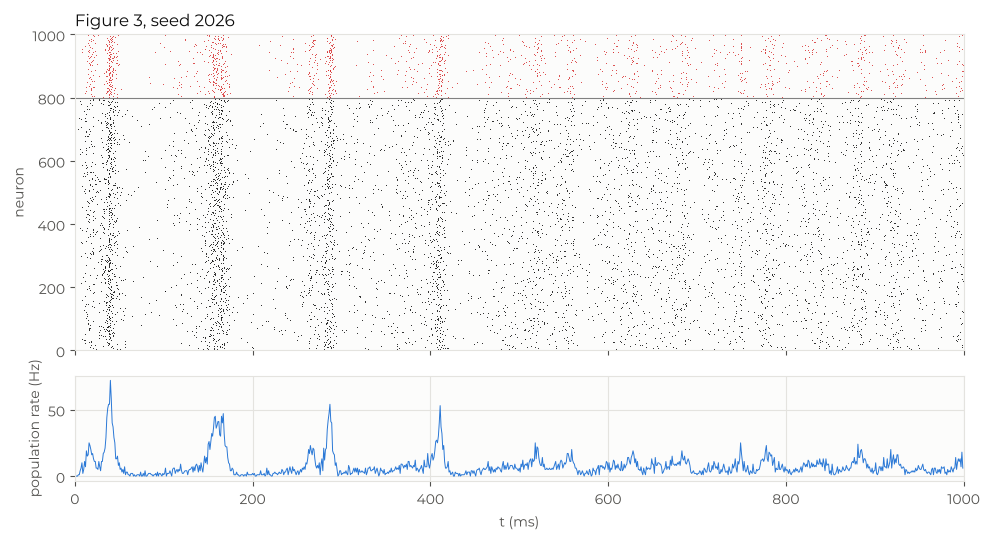

In [24]:
T = 1000

f_lit = network_literal(network_parameters(seed = SEED), T = T)

print_metrics('Literal network, whole simulation:', metrics(f_lit, T))
print_metrics('Without the initial transient (t > 100 ms):', metrics(f_lit, T, start = 100))

freqs, power = spectrum(f_lit, T)
print('Spectral peak of the population rate (t > 100 ms):', freqs[np.argmax(power)], 'Hz')

t_bins, rate = population_activity(f_lit, T)

fig, ax = plt.subplots(2, 1, figsize = (10, 5.5), sharex = True, gridspec_kw = {'height_ratios': [3, 1]})

raster(ax[0], f_lit)
ax[0].set_title(f'Figure 3, seed {SEED}')

ax[1].plot(t_bins, rate, lw = 0.7, color = COLOR)
ax[1].set_ylabel('population rate (Hz)')
ax[1].set_xlabel('t (ms)')

plt.tight_layout()
plt.show()

Asynchronous background activity can be seen (scattered spikes, ~7–8 Hz per neuron), interrupted by episodes of synchronisation: vertical bands in which a large part of the population fires together, with a rhythm close to alpha (≈ 8–10 Hz in the spectrum). The first episode (t ≈ 40 ms) is a transient: all neurons start at $v = -65$.

## 22. With and without self-connections (same seed)

The dense MATLAB matrix does not set the diagonal to zero: there are $s_{ii} \neq 0$. We compare with $s_{ii} = 0$; with the same seed, both versions share $r_i$, $S$ off the diagonal and the noise. Then the comparison is repeated with 20 seeds, using the mean rate for $t > 100$ ms.

With diagonal:
    spikes          : 7765
    mean rate (Hz)  : 7.765
    excitatory (Hz) : 7.815
    inhibitory (Hz) : 7.565
Without diagonal:
    spikes          : 7561
    mean rate (Hz)  : 7.561
    excitatory (Hz) : 7.644
    inhibitory (Hz) : 7.23


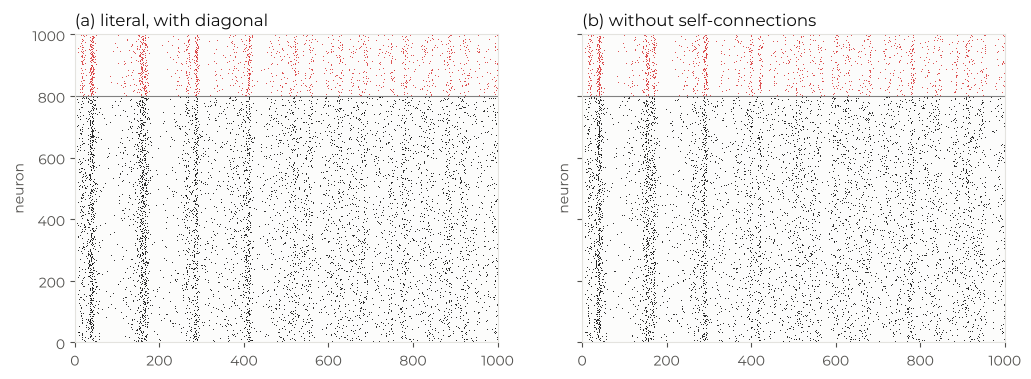

20 seeds, mean rate for t > 100 ms (mean ± standard deviation):
    with diagonal    : 7.19 ± 0.13 Hz
    without diagonal : 7.17 ± 0.13 Hz
    difference       : 0.021 ± 0.115 Hz


In [25]:
f_without = network_literal(network_parameters(seed = SEED, self_connections = False), T = T)

print_metrics('With diagonal:', metrics(f_lit, T))
print_metrics('Without diagonal:', metrics(f_without, T))

fig, ax = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

raster(ax[0], f_lit)
ax[0].set_title('(a) literal, with diagonal')

raster(ax[1], f_without)
ax[1].set_title('(b) without self-connections')

plt.show()

rates_with    = []
rates_without = []

for seed in range(1, 21):
    f_with_seed    = network_literal(network_parameters(seed = seed, self_connections = True),  T = T)
    f_without_seed = network_literal(network_parameters(seed = seed, self_connections = False), T = T)

    rates_with.append(metrics(f_with_seed, T, start = 100)['rate_Hz'])
    rates_without.append(metrics(f_without_seed, T, start = 100)['rate_Hz'])

rates_with    = np.array(rates_with)
rates_without = np.array(rates_without)
difference    = rates_with - rates_without

print('20 seeds, mean rate for t > 100 ms (mean ± standard deviation):')
print('    with diagonal    :', round(rates_with.mean(), 2), '±', round(rates_with.std(), 2), 'Hz')
print('    without diagonal :', round(rates_without.mean(), 2), '±', round(rates_without.std(), 2), 'Hz')
print('    difference       :', round(difference.mean(), 3), '±', round(difference.std(), 3), 'Hz')

The diagonal contributes a single weight to each neuron (≤ 0.5 mV if it is excitatory, ≥ −1 mV if it is inhibitory) against the sum of ~1000 inputs: removing it changes the individual spikes (the trajectories diverge because of the chaos of the network) but not the statistics or the qualitative dynamics.

## 23. Optional extra: Euler–Maruyama with continuous white noise

Between spikes, $dV_i = (0.04V_i^2 + 5V_i + 140 - U_i)\,dt + \sigma_i\,dW_i$ and $dU_i = a_i(b_iV_i - U_i)\,dt$, with $\sigma_i = 5$ (excitatory) or 2 (inhibitory), keeping the synaptic jumps and the reset separate. The Wiener increment over a step $h$ has variance $h$, which is why $\sqrt h$ appears: $Y_{n+1} = Y_n + f(Y_n)\,h + \sigma \sqrt h\,\xi_n$. In the original MATLAB code there is **no** $\sqrt h$: there the noise is a current drawn once per millisecond (a discrete sequence), not a Wiener process.

In [26]:
def network_euler_maruyama(p, T = 1000.0, h = 0.1):
    sigma = np.concatenate([5 * np.ones(p['Ne']), 2 * np.ones(p['Ni'])])

    v = -65.0 * np.ones(p['N'])
    u = p['b'] * v

    k = int(round(T / h))

    firings = []

    for n in range(k):
        fired = np.flatnonzero(v >= 30)

        for i in fired:
            firings.append([n * h, i])

        v[fired] = p['c'][fired]                           # reset
        u[fired] = u[fired] + p['d'][fired]

        v = v + p['S'][:, fired].sum(axis = 1)             # synaptic jump (same amplitude as the original)

        fv = 0.04 * v**2 + 5 * v + 140 - u
        fu = p['a'] * (p['b'] * v - u)

        v = v + fv * h + sigma * np.sqrt(h) * p['rng'].standard_normal(p['N'])
        u = u + fu * h

    return np.array(firings, dtype = float).reshape(-1, 2)

## 24. Optional extra: continuous coupling with $z(v) = \frac{87 + v}{450} - 0.0193$

Explicit proposal: the pulse term is replaced by the continuous current $I^{syn}_i(t) = \sum_j s_{ij}\,z(v_j(t))$ (everything else as in the MATLAB code). $z(v)$ is not a spike detector: it is ≈ 0.03 at rest, so each neuron receives a background input all the time. **It is a different model from that of Figure 3**; it is used only as a comparative experiment.

In [27]:
def z(v):
    # z(v) = (87 + v)/450 - 0.0193, with v clipped at 30 mV (v can go above 30 within a step)
    return (87.0 + np.minimum(v, 30.0)) / 450.0 - 0.0193


def network_z(p, T = 1000):
    # Same as network_literal, but the synaptic input is continuous:
    #     I_syn,i(t) = sum_j s_ij z(v_j(t))      (instead of sum_{j in F} s_ij)
    v = -65.0 * np.ones(p['N'])
    u = p['b'] * v

    firings = []

    for t in range(T):
        I = thalamic_noise(p)
        I = I + p['S'] @ z(v)                              # continuous coupling (v before the reset)

        fired = np.flatnonzero(v >= 30)

        for i in fired:
            firings.append([t, i])

        v[fired] = p['c'][fired]
        u[fired] = u[fired] + p['d'][fired]

        v = v + 0.5 * (0.04 * v**2 + 5 * v + 140 - u + I)
        v = v + 0.5 * (0.04 * v**2 + 5 * v + 140 - u + I)
        u = u + p['a'] * (p['b'] * v - u)

    return np.array(firings, dtype = float).reshape(-1, 2)

## 25. Comparison of the variants

The three networks use the same seed. The rates are compared for $t > 100$ ms, leaving out the initial transient.

Note: in the $z(v)$ variant the product `S @ z(v)` is computed by the numerical library (BLAS), whose round-off can differ between computers. Since the network is chaotic, the exact spike counts of this variant may change slightly from one machine to another; the rates and the qualitative behaviour do not.

Literal (t > 100 ms):
    spikes          : 6784
    mean rate (Hz)  : 7.538
    excitatory (Hz) : 7.615
    inhibitory (Hz) : 7.228
Euler-Maruyama (t > 100 ms):
    spikes          : 7411
    mean rate (Hz)  : 8.234
    excitatory (Hz) : 8.126
    inhibitory (Hz) : 8.667
z(v) (t > 100 ms):
    spikes          : 7512
    mean rate (Hz)  : 8.347
    excitatory (Hz) : 8.406
    inhibitory (Hz) : 8.111
Euler-Maruyama, first 100 ms: 24357 spikes, between t = 3.5 and 33.4 ms
z(v), whole simulation      : 8804 spikes


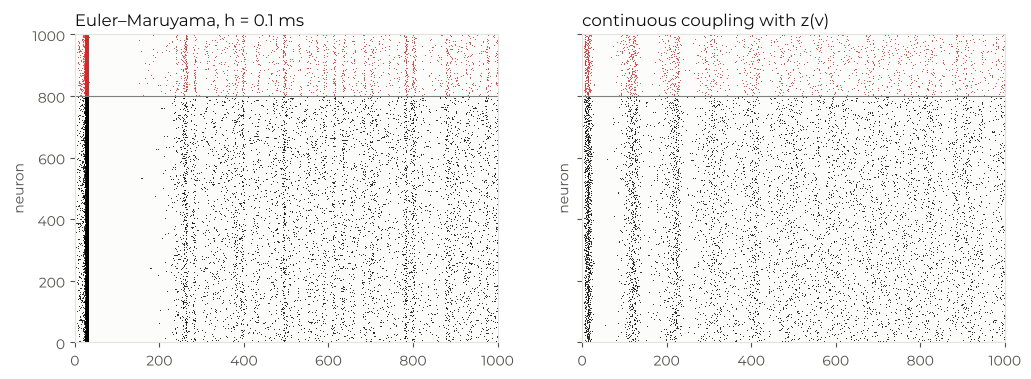

In [28]:
f_em = network_euler_maruyama(network_parameters(seed = SEED), T = T, h = 0.1)
f_z  = network_z(network_parameters(seed = SEED), T = T)

print_metrics('Literal (t > 100 ms):', metrics(f_lit, T, start = 100))
print_metrics('Euler-Maruyama (t > 100 ms):', metrics(f_em, T, start = 100))
print_metrics('z(v) (t > 100 ms):', metrics(f_z, T, start = 100))

early = f_em[f_em[:, 0] < 100]
print('Euler-Maruyama, first 100 ms:', len(early), 'spikes, between t =', round(early[:, 0].min(), 1), 'and', round(early[:, 0].max(), 1), 'ms')
print('z(v), whole simulation      :', len(f_z), 'spikes')

fig, ax = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

raster(ax[0], f_em)
ax[0].set_title('Euler–Maruyama, h = 0.1 ms')

raster(ax[1], f_z)
ax[1].set_title('continuous coupling with z(v)')

plt.show()

## 26. Population activity and spectrum

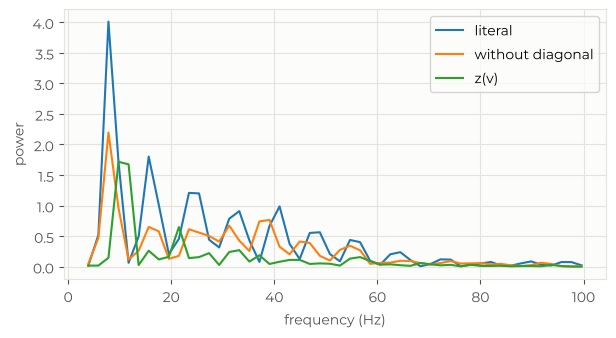

In [29]:
fig = plt.figure(figsize = (7, 3.5))

for label, firings in [('literal', f_lit), ('without diagonal', f_without), ('z(v)', f_z)]:
    freqs, power = spectrum(firings, T)
    keep = (freqs > 2) & (freqs < 100)
    plt.plot(freqs[keep], power[keep], label = label)

plt.xlabel('frequency (Hz)')
plt.ylabel('power')
plt.legend()
plt.show()

## 27. Part 2 in a compact figure

Figure for the report, one page wide (Figure 5). Top: raster plots of (a) the literal network, (b) the same network without self-connections, (c) the Euler–Maruyama variant and (d) the variant with $z(v)$. Bottom: population rate; on the left (a) and (b), on the right (a) in grey, (c) and (d).

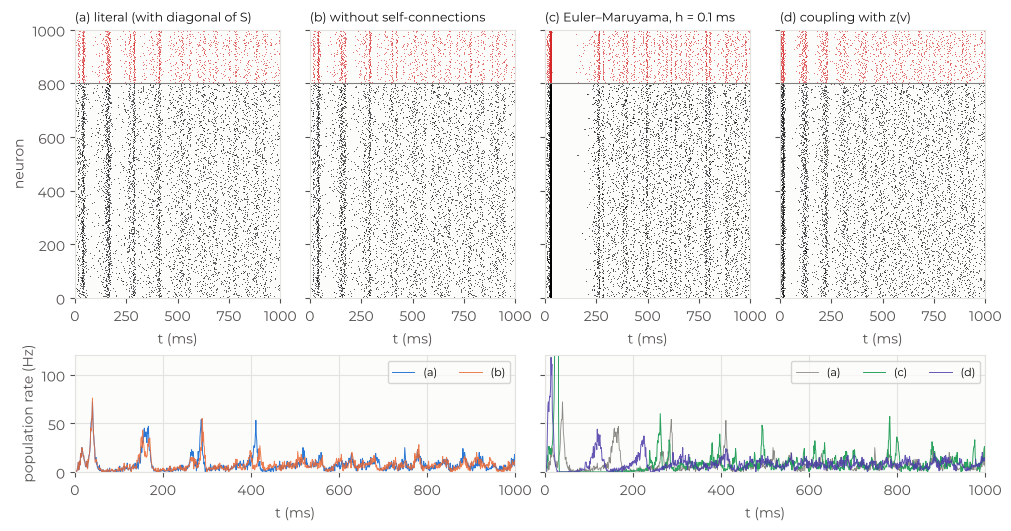

In [30]:
GREY   = '#8a8984'
VIOLET = '#4a3aa7'

titles  = ['(a) literal (with diagonal of S)', '(b) without self-connections', '(c) Euler–Maruyama, h = 0.1 ms', '(d) coupling with z(v)']
network = [f_lit, f_without, f_em, f_z]

fig = plt.figure(figsize = (10, 5.2), layout = 'constrained')
gs  = fig.add_gridspec(2, 4, height_ratios = [2.3, 1])

for j in range(4):
    axis = fig.add_subplot(gs[0, j])
    raster(axis, network[j], ms = 1.0)
    axis.set_title(titles[j], fontsize = 9)
    axis.set_xlabel('t (ms)')

    if j > 0:
        axis.set_ylabel('')
        axis.tick_params(labelleft = False)

rate_lit     = population_activity(f_lit, T)[1]
rate_without = population_activity(f_without, T)[1]
rate_em      = population_activity(f_em, T)[1]
rate_z       = population_activity(f_z, T)[1]
t_bins       = population_activity(f_lit, T)[0]

ax_left  = fig.add_subplot(gs[1, :2])
ax_right = fig.add_subplot(gs[1, 2:], sharey = ax_left)

ax_left.plot(t_bins, rate_lit,     lw = 0.7, color = COLOR,  label = '(a)')
ax_left.plot(t_bins, rate_without, lw = 0.7, color = ORANGE, label = '(b)', alpha = 0.85)

ax_right.plot(t_bins, rate_lit, lw = 0.6, color = GREY,   label = '(a)')
ax_right.plot(t_bins, rate_em,  lw = 0.7, color = GREEN,  label = '(c)')
ax_right.plot(t_bins, rate_z,   lw = 0.7, color = VIOLET, label = '(d)', alpha = 0.85)

for axis in [ax_left, ax_right]:
    axis.set_xlim(0, T)
    axis.set_ylim(0, 120)
    axis.set_xlabel('t (ms)')
    axis.legend(ncol = 3, loc = 'upper right', fontsize = 8)

ax_left.set_ylabel('population rate (Hz)')
ax_right.tick_params(labelleft = False)

plt.show()